<a href="https://colab.research.google.com/github/BrianLearning-source/PCVK_Genap_2026/blob/main/Week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# D. Practicum Task
D1. Fundamental Detection Object Practicum

In [2]:
# import required library
import cv2 as cv
import numpy as no
from matplotlib import pyplot as plt

In [3]:
# Access to drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


2. Implementation 6 method using cv.matchTemplate

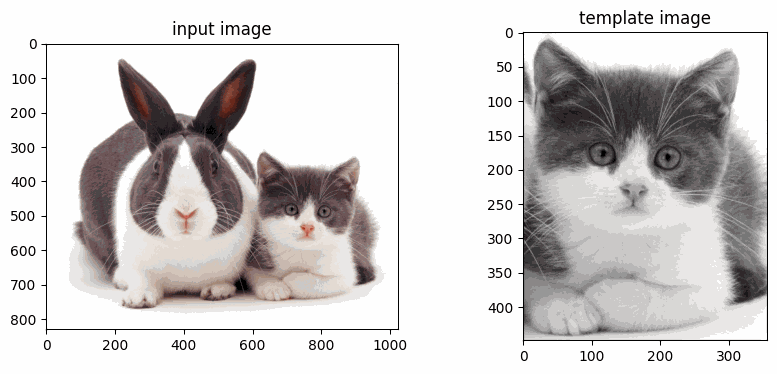

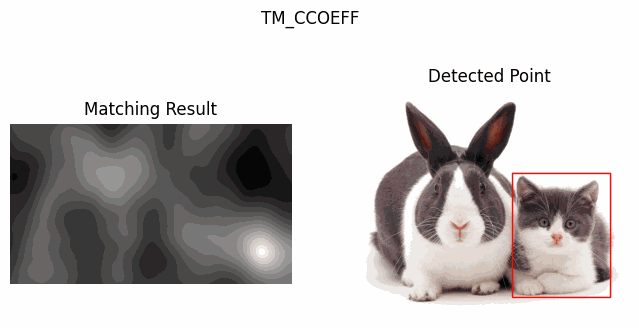

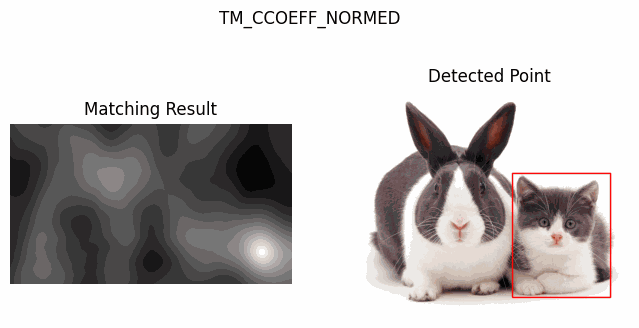

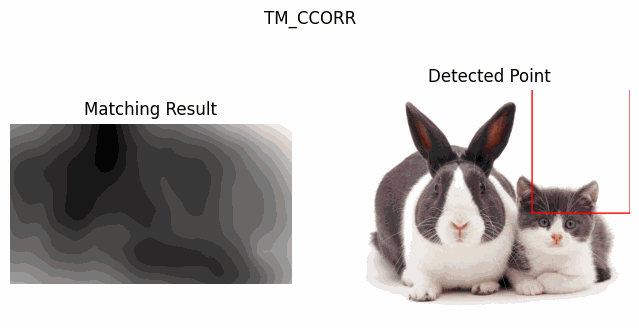

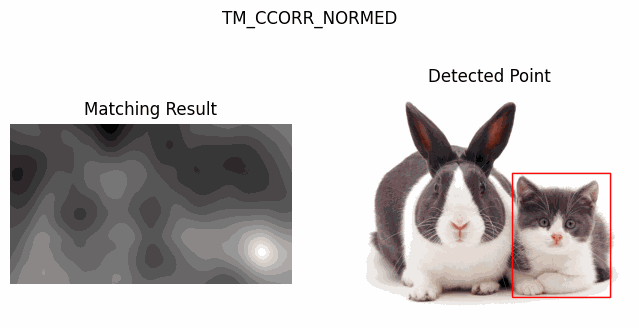

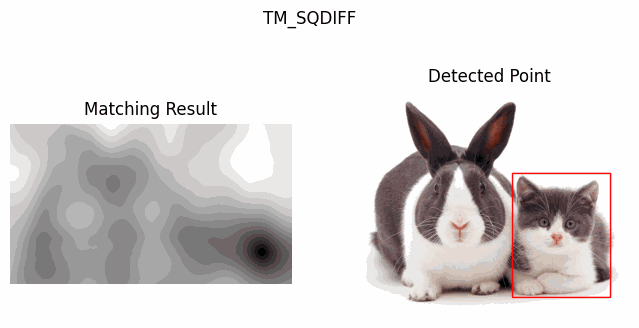

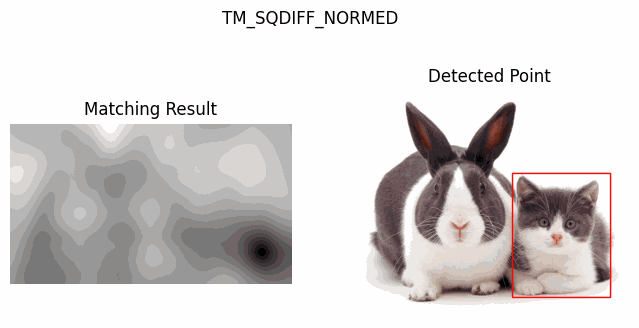

In [6]:
img = cv.imread('/content/drive/MyDrive/PCVK/Object Detection/cats_and_bunnies.jpg')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

template = cv.imread('/content/drive/MyDrive/PCVK/Object Detection/cat2_templatejpg.jpg',0)

w, h = template.shape[::-1]

fig = plt.figure(figsize=(10,4))

plt.subplot(121)
plt.imshow(cv.cvtColor(img,cv.COLOR_BGR2RGB))
plt.title('input image')

plt.subplot(122)
plt.imshow(template,cmap='gray')
plt.title('template image')

plt.show()

methods = [
    cv.TM_CCOEFF,
    cv.TM_CCOEFF_NORMED,
    cv.TM_CCORR,
    cv.TM_CCORR_NORMED,
    cv.TM_SQDIFF,
    cv.TM_SQDIFF_NORMED
]

method_names = [
    'TM_CCOEFF',
    'TM_CCOEFF_NORMED',
    'TM_CCORR',
    'TM_CCORR_NORMED',
    'TM_SQDIFF',
    'TM_SQDIFF_NORMED'
]

for meth, name in zip(methods, method_names):

    img2 = img.copy()

    result = cv.matchTemplate(
        img_gray,
        template,
        meth
    )

    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(result)

    if meth in [cv.TM_SQDIFF,
                cv.TM_SQDIFF_NORMED]:

        top_left = min_loc

    else:

        top_left = max_loc

    bottom_right = (
        top_left[0] + w,
        top_left[1] + h
    )

    cv.rectangle(
        img2,
        top_left,
        bottom_right,
        (0,0,255),
        3
    )

    plt.figure(figsize=(8,4))

    plt.subplot(121)
    plt.imshow(result,cmap='gray')
    plt.title('Matching Result')
    plt.axis('off')

    plt.subplot(122)
    plt.imshow(cv.cvtColor(
        img2,
        cv.COLOR_BGR2RGB
    ))
    plt.title('Detected Point')
    plt.axis('off')

    plt.suptitle(name)

    plt.show()

3. Implementation without using OpenCV library (cv.match)

Jumlah objek terdeteksi: 6


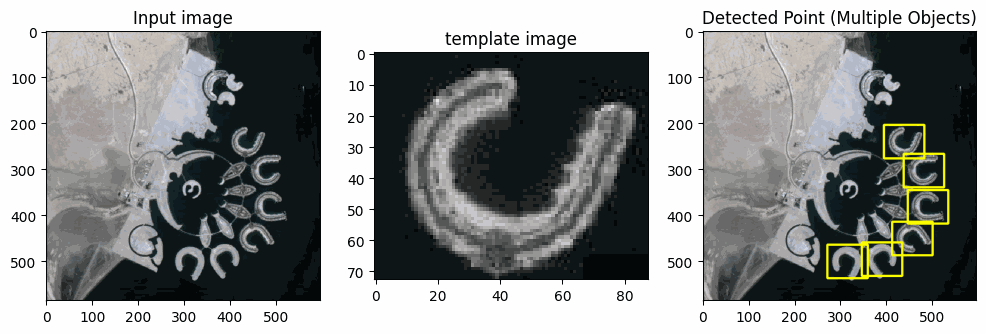

In [16]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Load citra input dan citra template dari Google Drive
img_path = '/content/drive/MyDrive/PCVK/Object Detection/bahrain.jpg'
template_path = '/content/drive/MyDrive/PCVK/Object Detection/bahrain-template.jpg'

img_gray = cv.imread(img_path, cv.IMREAD_GRAYSCALE)
template_gray = cv.imread(template_path, cv.IMREAD_GRAYSCALE)
img_rgb = cv.cvtColor(cv.imread(img_path), cv.COLOR_BGR2RGB)

h_template, w_template = template_gray.shape
h_img, w_img = img_gray.shape

# 2. Implementasi Template Matching Manual (Normalized Cross-Correlation)
result_h = h_img - h_template + 1
result_w = w_img - w_template + 1
match_result = np.zeros((result_h, result_w))

t_mean = np.mean(template_gray)
t_normalized = template_gray.astype(np.float32) - t_mean
t_norm_sum = np.sum(t_normalized ** 2)

for y in range(result_h):
    for x in range(result_w):
        patch = img_gray[y:y+h_template, x:x+w_template].astype(np.float32)
        p_mean = np.mean(patch)
        p_normalized = patch - p_mean
        p_norm_sum = np.sum(p_normalized ** 2)

        if t_norm_sum > 0 and p_norm_sum > 0:
            match_result[y, x] = np.sum(p_normalized * t_normalized) / np.sqrt(t_norm_sum * p_norm_sum)
        else:
            match_result[y, x] = 0

# 3. Turunkan Threshold agar objek target tertangkap dengan baik
threshold = 0.45  # Bisa disesuaikan jika kurang/lebih
detected_locations = []

y_indices, x_indices = np.where(match_result >= threshold)
for y, x in zip(y_indices, x_indices):
    detected_locations.append((x, y, match_result[y, x]))

# Urutkan berdasarkan skor kecocokan tertinggi
detected_locations = sorted(detected_locations, key=lambda item: item[2], reverse=True)

# 4. Non-Maximum Suppression (NMS) untuk menyaring kotak agar tidak menumpuk
filtered_boxes = []
min_distance = 35  # Jarak minimum piksel antar objek

for pt in detected_locations:
    x, y, score = pt
    overlap = False
    for fx, fy, _ in filtered_boxes:
        if abs(x - fx) < min_distance and abs(y - fy) < min_distance:
            overlap = True
            break
    if not overlap:
        filtered_boxes.append(pt)  # <-- INI BAGIAN YANG SEBELUMNYA KETINGGALAN

print(f"Jumlah objek terdeteksi: {len(filtered_boxes)}")

# 5. Gambar Kotak Pembatas (Bounding Boxes) warna Kuning
output_img = img_rgb.copy()
for x, y, _ in filtered_boxes:
    cv.rectangle(output_img, (x, y), (x + w_template, y + h_template), (255, 255, 0), 3)

# 6. Plotting Hasil Sesuai Format Modul
plt.figure(figsize=(12, 6))

plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title("Input image")
plt.axis('on')

plt.subplot(1, 3, 2)
plt.imshow(cv.cvtColor(template_gray, cv.COLOR_GRAY2BGR))
plt.title('template image')
plt.axis('on')

plt.subplot(1, 3, 3)
plt.imshow(output_img)
plt.title("Detected Point (Multiple Objects)")
plt.axis('on')

plt.show()

4. Implementation Sobel Detection method, canny Edge Detection, and Laplacian Edge Detecyion using OpenCV

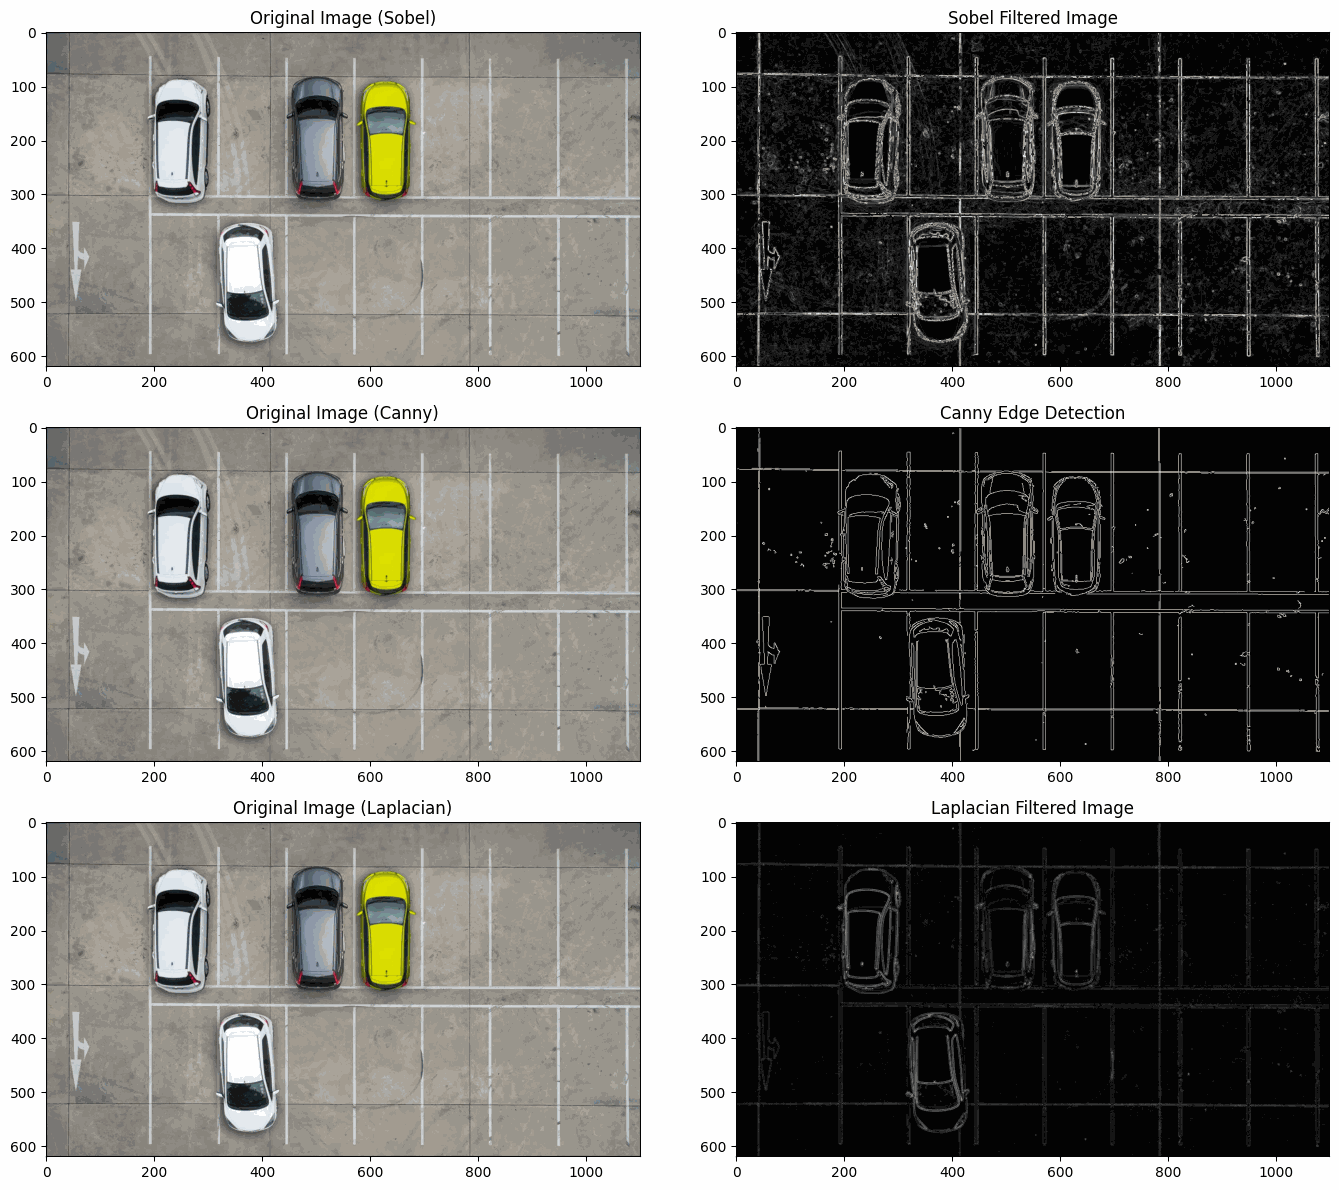

In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load citra input dari Google Drive
car_park_path = '/content/drive/MyDrive/PCVK/Object Detection/car-park.jpg'

# Baca gambar dalam bentuk Grayscale untuk proses deteksi tepi
img_gray = cv2.imread(car_park_path, cv2.IMREAD_GRAYSCALE)
# Baca gambar dalam format RGB untuk ditampilkan dengan matplotlib
img_rgb = cv2.cvtColor(cv2.imread(car_park_path), cv2.COLOR_BGR2RGB)

# 2. a. Sobel Edge Detection
# Menghitung gradien arah X dan Y menggunakan kernel ukuran 3x3
sobel_x = cv2.Sobel(img_gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(img_gray, cv2.CV_64F, 0, 1, ksize=3)
# Menggabungkan gradien X dan Y (menggunakan nilai absolut)
sobel_combined = cv2.magnitude(sobel_x, sobel_y)
# Konversi kembali ke unit8 agar bisa dirender dengan benar
sobel_combined = np.uint8(np.absolute(sobel_combined))

# 2. b. Canny Edge Detection
# Menerapkan Canny dengan threshold bawah dan atas (misal: 100 dan 200)
canny_edges = cv2.Canny(img_gray, 100, 200)

# 2. c. Laplacian Edge Detection
# Menghaluskan gambar terlebih dahulu dengan Gaussian Blur untuk mengurangi noise
blurred = cv2.GaussianBlur(img_gray, (3, 3), 0)
laplacian = cv2.Laplacian(blurred, cv2.CV_64F)
laplacian_edges = np.uint8(np.absolute(laplacian))

# 3. Plotting dan Visualisasi Hasil Sesuai Format Modul
plt.figure(figsize=(14, 12))

# --- Plot Sobel ---
plt.subplot(3, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Image (Sobel)")
plt.axis('on')

plt.subplot(3, 2, 2)
plt.imshow(sobel_combined, cmap='gray')
plt.title("Sobel Filtered Image")
plt.axis('on')

# --- Plot Canny ---
plt.subplot(3, 2, 3)
plt.imshow(img_rgb)
plt.title("Original Image (Canny)")
plt.axis('on')

plt.subplot(3, 2, 4)
plt.imshow(canny_edges, cmap='gray')
plt.title("Canny Edge Detection")
plt.axis('on')

# --- Plot Laplacian ---
plt.subplot(3, 2, 5)
plt.imshow(img_rgb)
plt.title("Original Image (Laplacian)")
plt.axis('on')

plt.subplot(3, 2, 6)
plt.imshow(laplacian_edges, cmap='gray')
plt.title("Laplacian Filtered Image")
plt.axis('on')

plt.tight_layout()
plt.show()

5. Implementation Harris Corner method and Shi-Tomasi Detection for OpenCV

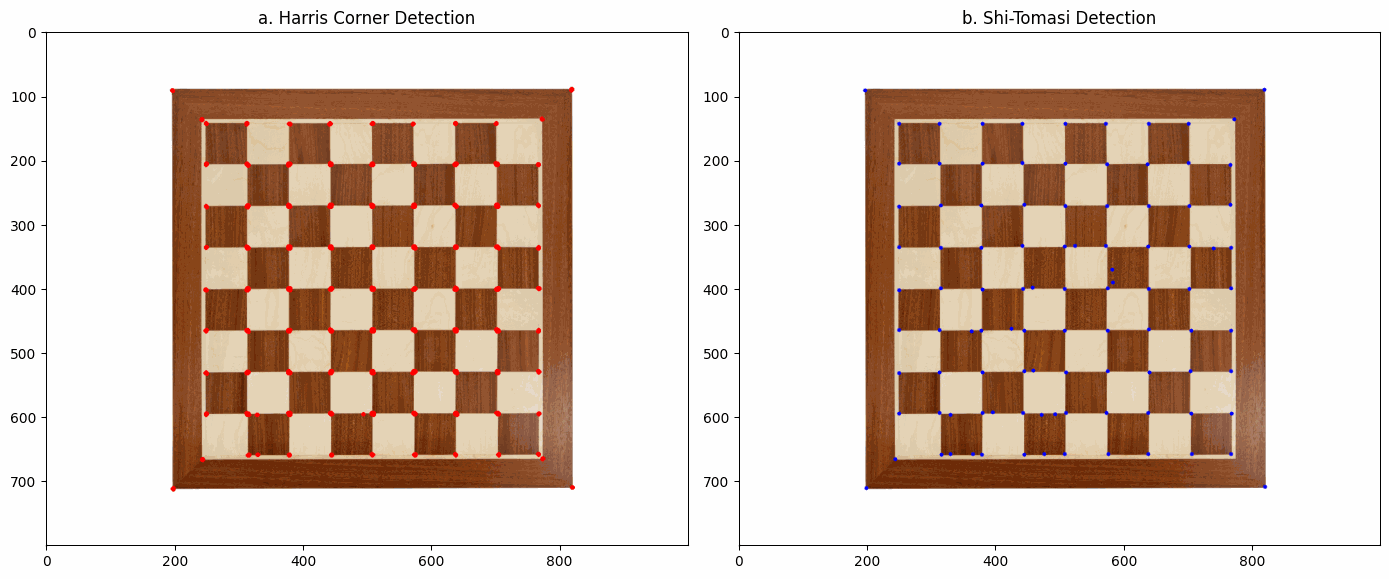

In [18]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load citra input dari Google Drive
chess_path = '/content/drive/MyDrive/PCVK/Object Detection/chess-board.jpg'
img_gray = cv2.imread(chess_path, cv2.IMREAD_GRAYSCALE)
img_rgb = cv2.cvtColor(cv2.imread(chess_path), cv2.COLOR_BGR2RGB)

# -------------------------------------------------------------
# 2. a. Harris Corner Detection (Dibuat titik merah seperti modul)
# -------------------------------------------------------------
gray_harris = np.float32(img_gray)
harris_result = cv2.cornerHarris(gray_harris, blockSize=2, ksize=3, k=0.04)

# Dilatasi untuk mempertegas area sudut
harris_result = cv2.dilate(harris_result, None)

# Cari koordinat piksel yang nilai harris-nya di atas threshold (misal 0.01 * max)
img_harris = img_rgb.copy()
threshold_harris = 0.01 * harris_result.max()

# Mengubah titik-titik sudut Harris menjadi lingkaran merah (sesuai modul)
for y in range(harris_result.shape[0]):
    for x in range(harris_result.shape[1]):
        if harris_result[y, x] > threshold_harris:
            # Gambar titik/lingkaran merah kecil pada sudut Harris
            cv2.circle(img_harris, (x, y), 2, (255, 0, 0), -1) # Warna merah di RGB

# -------------------------------------------------------------
# 2. b. Shi-Tomasi Detection (Titik biru seperti modul)
# -------------------------------------------------------------
corners = cv2.goodFeaturesToTrack(img_gray, maxCorners=100, qualityLevel=0.01, minDistance=10)
corners = np.int64(corners)

img_shitomasi = img_rgb.copy()
for i in corners:
    x, y = i.ravel()
    # Gambar lingkaran biru pada sudut Shi-Tomasi
    cv2.circle(img_shitomasi, (x, y), 3, (0, 0, 255), -1) # Warna biru di RGB (BGR format di-convert ke RGB)

# -------------------------------------------------------------
# 3. Plotting Hasil
# -------------------------------------------------------------
plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
plt.imshow(img_harris)
plt.title("a. Harris Corner Detection")
plt.axis('on')

plt.subplot(1, 2, 2)
plt.imshow(img_shitomasi)
plt.title("b. Shi-Tomasi Detection")
plt.axis('on')

plt.tight_layout()
plt.show()

6. Implementation Hough Transoform for OpenCV

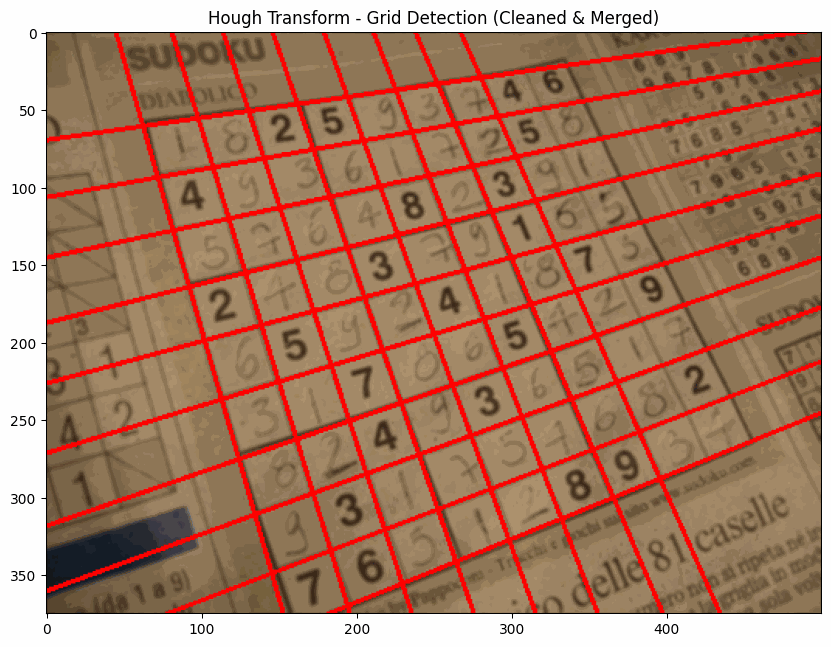

In [19]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load citra input sudoku dari Google Drive
sudoku_path = '/content/drive/MyDrive/PCVK/Object Detection/sudoku.jpg'
img_gray = cv2.imread(sudoku_path, cv2.IMREAD_GRAYSCALE)
img_rgb = cv2.cvtColor(cv2.imread(sudoku_path), cv2.COLOR_BGR2RGB)

# 2. Tahapan Grid Detection (Canny -> Dilasi -> Erosi)
edges = cv2.Canny(img_gray, 50, 150, apertureSize=3)

kernel = np.ones((3, 3), np.uint8)
dilated = cv2.dilate(edges, kernel, iterations=1)
eroded = cv2.erode(dilated, kernel, iterations=1)

# 3. Menerapkan HoughLines dengan threshold yang lebih tinggi agar garis acak berkurang
lines = cv2.HoughLines(eroded, 1, np.pi / 180, 240)

# 4. Fungsi untuk menyaring/menggabungkan garis yang terlalu berdekatan (similar lines)
def filter_similar_lines(lines, rho_thresh=15, theta_thresh=np.pi/30):
    filtered = []
    if lines is not None:
        for line in lines:
            rho, theta = line[0]
            # Abaikan garis miring/diagonal (coretan)
            angle = theta * 180.0 / np.pi
            if (angle > 25 and angle < 65) or (angle > 115 and angle < 155):
                continue

            is_duplicate = False
            for f_rho, f_theta in filtered:
                if abs(rho - f_rho) < rho_thresh and abs(theta - f_theta) < theta_thresh:
                    is_duplicate = True
                    break
            if not is_duplicate:
                filtered.append((rho, theta))
    return filtered

unique_lines = filter_similar_lines(lines)

# 5. Gambar garis hasil filter yang bersih dan merentang ke tepi
img_hough = img_rgb.copy()
for rho, theta in unique_lines:
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a * rho
    y0 = b * rho

    x1 = int(x0 + 1000 * (-b))
    y1 = int(y0 + 1000 * (a))
    x2 = int(x0 - 1000 * (-b))
    y2 = int(y0 - 1000 * (a))

    cv2.line(img_hough, (x1, y1), (x2, y2), (255, 0, 0), 2)

# 6. Tampilkan Hasil
plt.figure(figsize=(10, 8))
plt.imshow(img_hough)
plt.title("Hough Transform - Grid Detection (Cleaned & Merged)")
plt.axis('on')
plt.show()

7. Implementation findCountours() function for OpenCV

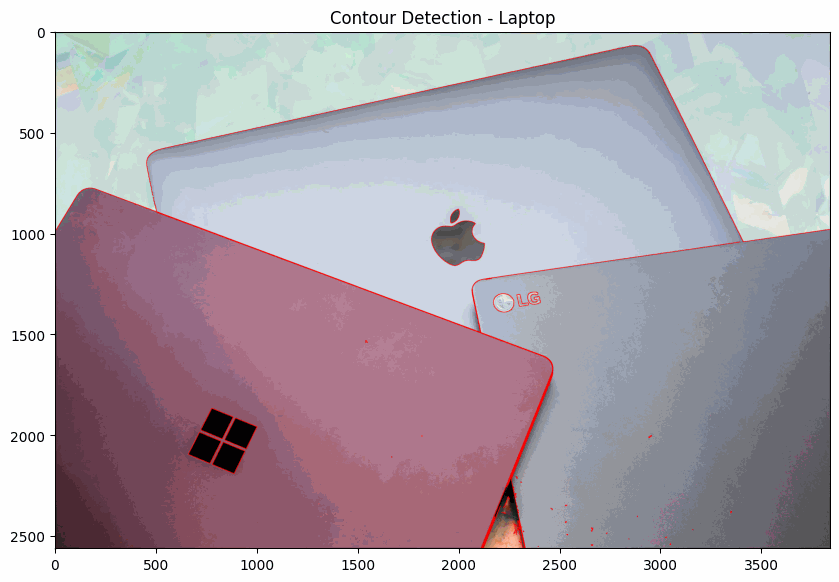

In [20]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load citra input laptop dari Google Drive
laptop_path = '/content/drive/MyDrive/PCVK/Object Detection/laptop.jpg'
img_gray = cv2.imread(laptop_path, cv2.IMREAD_GRAYSCALE)
img_rgb = cv2.cvtColor(cv2.imread(laptop_path), cv2.COLOR_BGR2RGB)

# 2. Ubah citra input menjadi citra biner menggunakan Canny Edge Detection
# Threshold (50, 150) dapat mendeteksi tepi bodi laptop dengan baik
edges = cv2.Canny(img_gray, 50, 150)

# 3. Menemukan kontur menggunakan fungsi findContours()
# Menggunakan cv2.RETR_EXTERNAL untuk mengambil kontur luar (paling luar) dari objek laptop
contours, hierarchy = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# 4. Menggambarkan kontur pada salinan citra asli menggunakan drawContours()
img_contour = img_rgb.copy()
# Parameter: gambar_tujuan, kontur, indeks_kontur (-1 untuk semua), warna (Merah dalam RGB = 255,0,0), ketebalan = 2
cv2.drawContours(img_contour, contours, -1, (255, 0, 0), 2)

# 5. Tampilkan Hasil Menggunakan Matplotlib
plt.figure(figsize=(10, 8))
plt.imshow(img_contour)
plt.title("Contour Detection - Laptop")
plt.axis('on')
plt.show()

D2. Feature Matching Practicum and Face Detection

8. Do Face Detection for object image

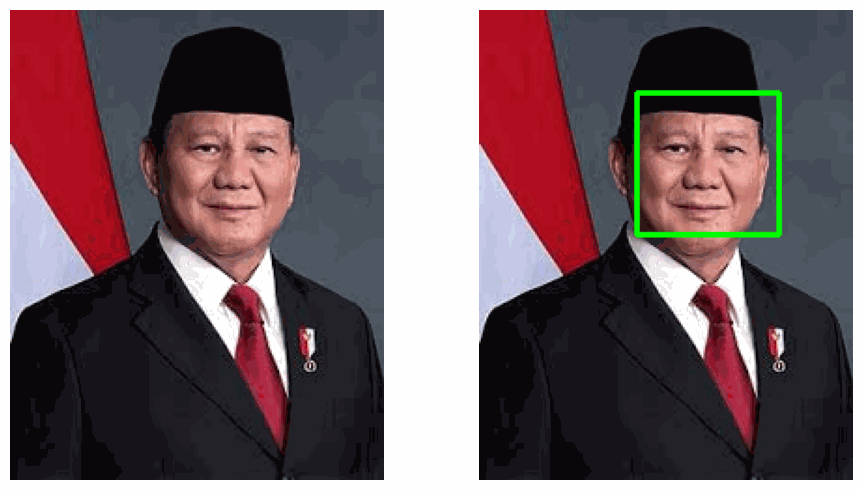

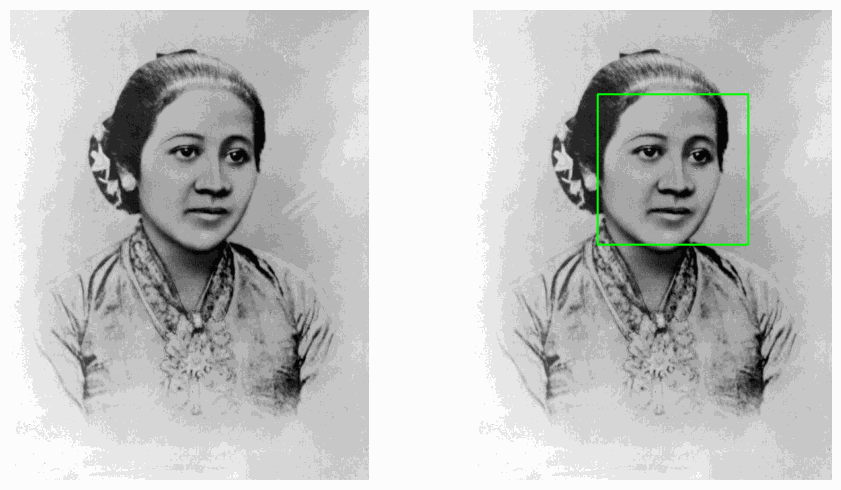

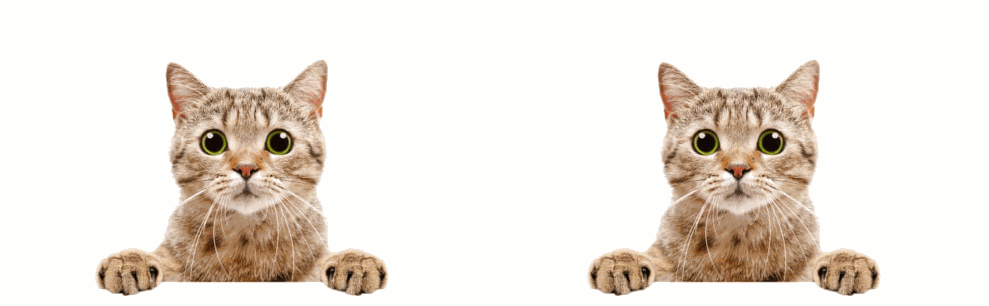

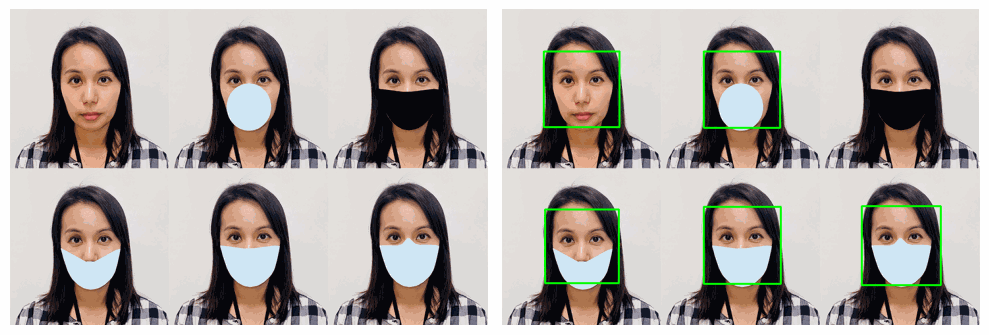

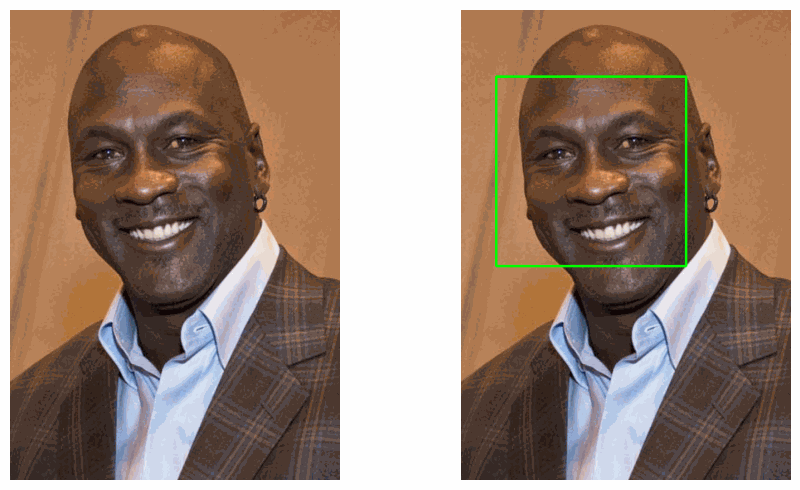

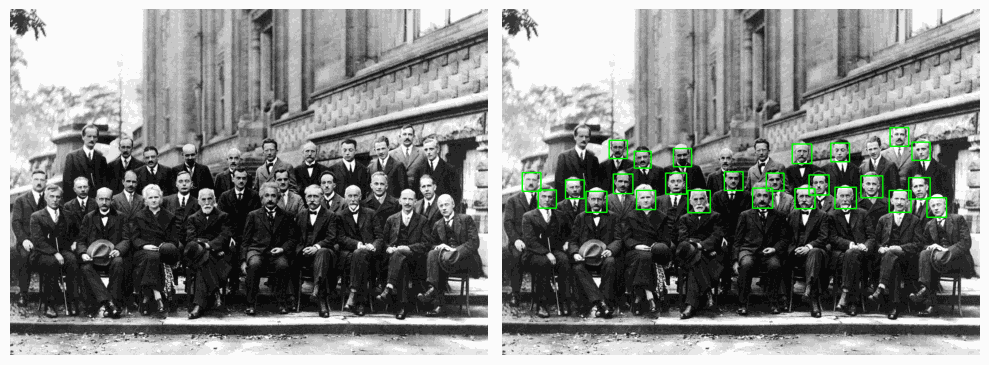

In [27]:
import cv2 as cv
import os
import matplotlib.pyplot as plt

# 1. Tentukan path folder tempat gambar-gambar facedet berada di Google Drive
prabowo = '/content/drive/MyDrive/PCVK/facedet/Prabowo.jpg'
kartini = '/content/drive/MyDrive/PCVK/facedet/kartini.jpg'
kucing = '/content/drive/MyDrive/PCVK/facedet/kucing.jpg'
mask = '/content/drive/MyDrive/PCVK/facedet/mask.png'
mjordan = '/content/drive/MyDrive/PCVK/facedet/mjordan.jpg'
solvayconf = '/content/drive/MyDrive/PCVK/facedet/solvayconf.jpg'

# 2. Buat fungsi untuk memproses deteksi wajah dengan parameter path gambar
def deteksi_wajah(image_path):
    # Load Haar Cascade bawaan OpenCV
    cascade_wajah = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_frontalface_alt.xml')

    # Baca gambar asli (mentah)
    img = cv.imread(image_path)
    if img is None:
        print(f"Gagal membaca gambar: {image_path}")
        return

    # Konversi ke Grayscale untuk proses deteksi
    img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # Konversi ke RGB untuk ditampilkan dengan Matplotlib
    img_raw_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
    img_result_rgb = img_raw_rgb.copy()

    # Lakukan deteksi wajah (detectMultiScale)
    faces = cascade_wajah.detectMultiScale(img_gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))

    # Gambar kotak (rectangle) pada wajah yang terdeteksi
    for (x, y, w, h) in faces:
        cv.rectangle(img_result_rgb, (x, y), (x + w, y + h), (0, 255, 0), 2)  # Warna hijau

    # 3. Tampilkan menggunakan subplot (Kiri: Gambar Mentah, Kanan: Hasil Deteksi)
    plt.figure(figsize=(10, 5))

    # Subplot Kiri: Gambar Mentah
    plt.subplot(1, 2, 1)
    plt.imshow(img_raw_rgb)
    plt.axis('off')

    # Subplot Kanan: Gambar Hasil Deteksi
    plt.subplot(1, 2, 2)
    plt.imshow(img_result_rgb)
    plt.axis('off')

    plt.tight_layout()
    plt.show()

image_list = [prabowo, kartini, kucing, mask, mjordan, solvayconf]
# Panggil fungsi deteksi dengan parameter path gambar
for image_path in image_list:
  deteksi_wajah(image_path)

9. Doing face cat detection using xml

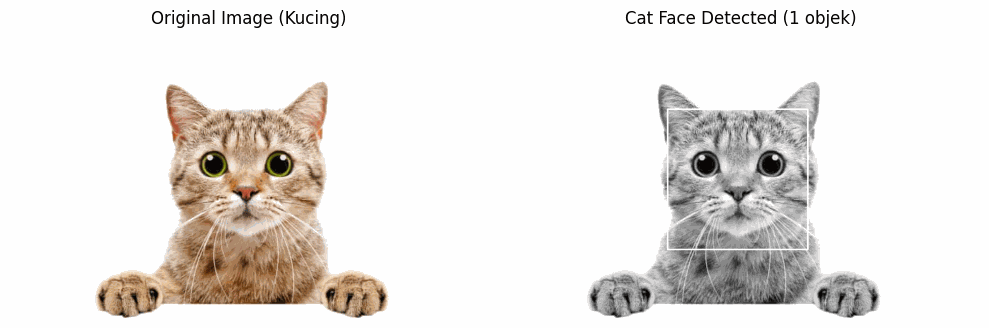

In [36]:
import cv2 as cv
import os
import matplotlib.pyplot as plt

# 1. Tentukan path masing-masing gambar secara spesifik
kucing_path = '/content/drive/MyDrive/PCVK/facedet/kucing.jpg'

# Tentukan path lengkap menuju file XML khusus wajah kucing di foldermu
xml_kucing_path = '/content/drive/MyDrive/PCVK/haarcascades/haarcascade_frontalcatface.xml'

# 2. Buat fungsi untuk memproses deteksi wajah kucing dengan parameter path gambar dan path xml
def deteksi_wajah_kucing(image_path, xml_path):
    # Cek apakah file gambar ada
    if not os.path.exists(image_path):
        print(f"[ERROR] File gambar tidak ditemukan di path: {image_path}")
        return

    # Load Cascade Classifier khusus wajah kucing (.xml) dari folder yang kamu miliki
    cascade_kucing = cv.CascadeClassifier(xml_path)
    if cascade_kucing.empty():
        print(f"[ERROR] Gagal memuat file XML dari path: {xml_path}")
        return

    # Baca gambar asli (mentah)
    img = cv.imread(image_path)
    if img is None:
        print(f"[ERROR] Gagal membaca gambar: {image_path}")
        return

    # Konversi gambar asli ke RGB untuk subplot kiri (gambar mentah berwarna)
    img_raw_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

    # Konversi gambar asli ke Grayscale untuk proses deteksi dan subplot kanan
    img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # Konversi grayscale ke RGB agar Matplotlib bisa menampilkannya dalam nuansa abu-abu
    img_result_rgb = cv.cvtColor(img_gray, cv.COLOR_GRAY2RGB)

    # Lakukan deteksi wajah kucing menggunakan detectMultiScale
    faces = cascade_kucing.detectMultiScale(
        img_gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(80, 80)
    )

    # Gambar kotak (rectangle) pada wajah kucing yang terdeteksi di gambar abu-abu
    for (x, y, w, h) in faces:
        cv.rectangle(img_result_rgb, (x, y), (x + w, y + h), (255, 255, 255), 2)  # Warna putih

    # 3. Tampilkan menggunakan subplot (Kiri: Gambar Mentah Berwarna, Kanan: Hasil Deteksi Abu-abu)
    plt.figure(figsize=(10, 5))

    # Subplot Kiri: Gambar Mentah (Tetap Berwarna)
    plt.subplot(1, 2, 1)
    plt.imshow(img_raw_rgb)
    plt.title("Original Image (Kucing)")
    plt.axis('off')

    # Subplot Kanan: Gambar Hasil Deteksi (Abu-abu dengan Kotak)
    plt.subplot(1, 2, 2)
    plt.imshow(img_result_rgb)
    plt.title(f"Cat Face Detected ({len(faces)} objek)")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# Panggil fungsi deteksi dengan parameter path gambar dan path file xml yang benar
deteksi_wajah_kucing(kucing_path, xml_kucing_path)

10. Trying eyes detection for Mr. Prabowo face

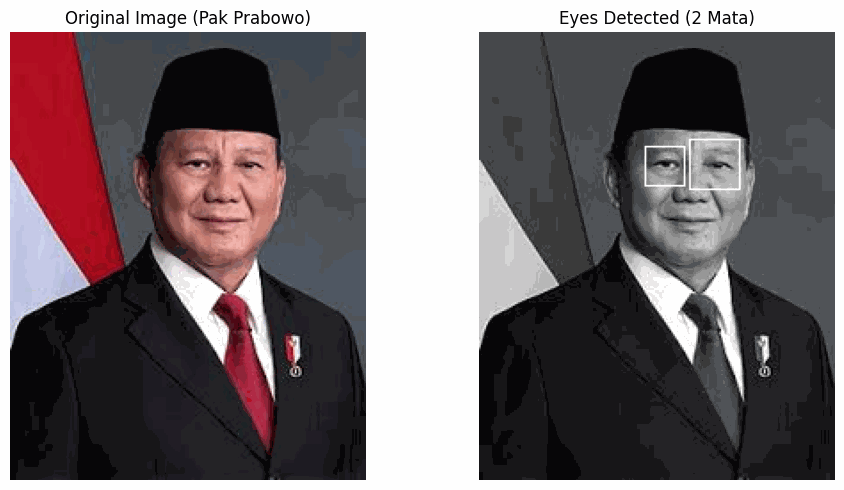

In [43]:
import cv2 as cv
import os
import matplotlib.pyplot as plt

# 1. Tentukan path gambar Pak Prabowo dan file XML mata
prabowo_path = '/content/drive/MyDrive/PCVK/facedet/Prabowo.jpg'
xml_eye_path = cv.data.haarcascades + 'haarcascade_eye.xml'
xml_face_path = cv.data.haarcascades + 'haarcascade_frontalface_alt.xml'

# 2. Buat fungsi untuk memproses deteksi mata (hanya kotak mata)
def deteksi_mata_saja(image_path, face_xml, eye_xml):
    if not os.path.exists(image_path):
        print(f"[ERROR] File gambar tidak ditemukan di path: {image_path}")
        return

    cascade_wajah = cv.CascadeClassifier(face_xml)
    cascade_mata = cv.CascadeClassifier(eye_xml)

    img = cv.imread(image_path)
    if img is None:
        print(f"[ERROR] Gagal membaca gambar: {image_path}")
        return

    img_raw_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
    img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # Konversi ke Grayscale untuk ditampilkan dengan nuansa abu-abu
    img_result_rgb = cv.cvtColor(img_gray, cv.COLOR_GRAY2RGB)

    # Deteksi Wajah
    faces = cascade_wajah.detectMultiScale(img_gray, scaleFactor=1.1, minNeighbors=5, minSize=(50, 50))

    eyes_count = 0
    for (x, y, w, h) in faces:
        # (BARIS KOTAK WAJAH DIHAPUS AGAR TIDAK MUNCUL KOTAK DI WAJAH)

        # Ambil region of interest (ROI) pada area wajah bagian atas
        roi_gray = img_gray[y:y+int(h*0.6), x:x+w]
        roi_color = img_result_rgb[y:y+int(h*0.6), x:x+w]

        # Deteksi mata
        eyes = cascade_mata.detectMultiScale(roi_gray, scaleFactor=1.1, minNeighbors=1, minSize=(15, 15))
        eyes_count = len(eyes)

        # Gambar kotak HANYA pada mata yang terdeteksi
        for (ex, ey, ew, eh) in eyes:
            # Karena koordinat (ex, ey) relatif terhadap roi, kita gambar di roi_color
            cv.rectangle(roi_color, (ex, ey), (ex + ew, ey + eh), (255, 255, 255), 1)

    # 3. Tampilkan menggunakan subplot
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(img_raw_rgb)
    plt.title("Original Image (Pak Prabowo)")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(img_result_rgb)
    plt.title(f"Eyes Detected ({eyes_count} Mata)")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# Panggil fungsi
deteksi_mata_saja(prabowo_path, xml_face_path, xml_eye_path)

11. Doing smile detection for people image

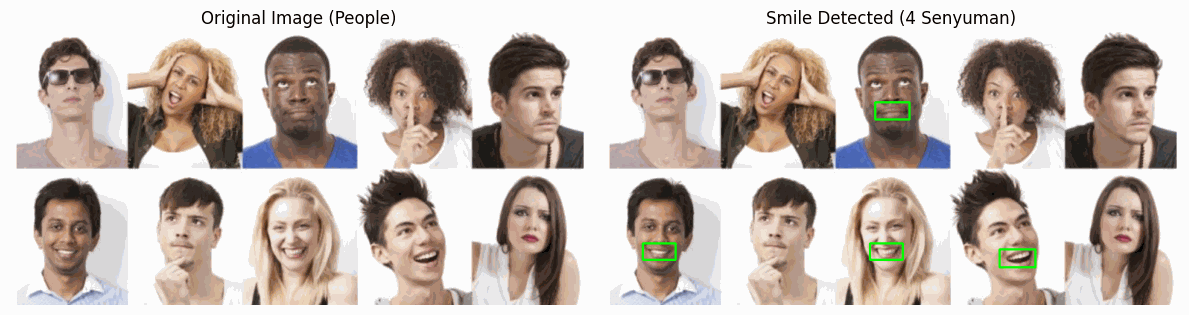

In [52]:
import cv2 as cv
import os
import matplotlib.pyplot as plt

# 1. Tentukan path gambar orang (grid people)
people_path = '/content/drive/MyDrive/PCVK/facedet/expression.png'

# Path file XML bawaan OpenCV
xml_face_path = cv.data.haarcascades + 'haarcascade_frontalface_alt.xml'
xml_smile_path = cv.data.haarcascades + 'haarcascade_smile.xml'

def deteksi_senyuman_stabil(image_path, face_xml, smile_xml):
    if not os.path.exists(image_path):
        print(f"[ERROR] File gambar tidak ditemukan di path: {image_path}")
        return

    cascade_wajah = cv.CascadeClassifier(face_xml)
    cascade_senyum = cv.CascadeClassifier(smile_xml)

    img = cv.imread(image_path)
    if img is None:
        print(f"[ERROR] Gagal membaca gambar: {image_path}")
        return

    img_raw_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
    img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    img_result_rgb = img_raw_rgb.copy()

    # Deteksi semua wajah dalam gambar grid
    faces = cascade_wajah.detectMultiScale(img_gray, scaleFactor=1.1, minNeighbors=3, minSize=(20, 20))

    total_senyuman = 0
    for (x, y, w, h) in faces:
        # Ambil region of interest (ROI) pada gambar berwarna asli (paruh bawah wajah)
        roi_gray = img_gray[y + int(h*0.4):y+h, x:x+w]
        roi_color = img_result_rgb[y + int(h*0.4):y+h, x:x+w]

        # Deteksi senyuman dengan minNeighbors=5 agar tidak terlalu sensitif ganda
        smiles = cascade_senyum.detectMultiScale(roi_gray, scaleFactor=1.2, minNeighbors=5, minSize=(15, 15))

        # Jika ada senyuman yang terdeteksi, ambil satu saja (kotak pertama/utama) untuk menghindari dobel
        if len(smiles) > 0:
            total_senyuman += 1
            # Ambil elemen pertama dari list smiles agar hanya tergambar 1 kotak per orang
            (sx, sy, sw, sh) = smiles[0]
            cv.rectangle(roi_color, (sx, sy), (sx + sw, sy + sh), (0, 255, 0), 2)

    # 3. Tampilkan menggunakan subplot
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(img_raw_rgb)
    plt.title("Original Image (People)")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(img_result_rgb)
    plt.title(f"Smile Detected ({total_senyuman} Senyuman)")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# Panggil fungsi
deteksi_senyuman_stabil(people_path, xml_face_path, xml_smile_path)